# K-Nearest Neighbors ? Acoustic Event Classification
### Sonobuoy Sound Detective: Offline Underwater Acoustic Event Detection
**Assigned Team Member:** Person 1  
**Algorithm:** Distance-weighted K-Nearest Neighbors  
**Workspace Folder:** `01_person1_lr_and_knn/`  
**Algorithm Identifier:** `knn`

---

## 1. Algorithm Overview & Theoretical Foundation

K-Nearest Neighbors (KNN) is an instance-based classifier. It stores the training examples and predicts a new sample from the labels of its nearest training samples:

$$d(\mathbf{x}, \mathbf{z}) = \sqrt{\sum_{j=1}^D (x_j-z_j)^2}$$

This notebook uses distance-weighted voting, so nearby samples have more influence than distant samples. Scaling is essential because the 66 acoustic features have different units and ranges.

This notebook:
1. Loads the shared feature table and selected acoustic features.
2. Uses the official train/validation/test split.
3. Uses `source_clip_id` for clip-grouped cross-validation.
4. Fits `StandardScaler` inside a pipeline during tuning.
5. Tunes neighbors, voting weights, and distance metric using macro F1.
6. Evaluates the selected model on validation and held-out test data.
7. Saves confusion matrix, ROC, tuning, and permutation-importance plots.
8. Exports and reloads the model artifacts for the final comparison.

The held-out test set is not used to select hyperparameters.

In [2]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, average_precision_score, auc, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedGroupKFold, learning_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
ALGO_NAME = "K-Nearest Neighbors"
FILE_SLUG = "knn"
Path("plots").mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)
print(f"Configured notebook for {ALGO_NAME} ({FILE_SLUG}).")

Configured notebook for K-Nearest Neighbors (knn).


## 2. Load Shared Acoustic Features and Selected Descriptors

In [3]:
FEATURES_PATH = Path("../data/features/features.csv")
SELECTED_FEATURES_PATH = Path("../data/features/selected_features.json")
if not FEATURES_PATH.exists():
    raise FileNotFoundError(f"Feature table not found: {FEATURES_PATH}")
if not SELECTED_FEATURES_PATH.exists():
    raise FileNotFoundError(f"Selected-feature file not found: {SELECTED_FEATURES_PATH}")

df = pd.read_csv(FEATURES_PATH)
with open(SELECTED_FEATURES_PATH, encoding="utf-8") as f:
    selected_data = json.load(f)
feature_cols = selected_data["selected_features"]

print("Dataset shape:", df.shape)
print("Selected feature count:", len(feature_cols))
print("Selected feature preview:", feature_cols[:10])
print("Data types:")
print(df[feature_cols].dtypes.value_counts())
print("Missing values in selected features:", int(df[feature_cols].isna().sum().sum()))
print("Infinite values in selected features:", int(np.isinf(df[feature_cols].to_numpy()).sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
assert len(feature_cols) == 66
assert not [c for c in feature_cols if c not in df.columns]
assert set(df["split"].unique()) == {"train", "val", "test"}


Dataset shape: (3579, 221)
Selected feature count: 66
Selected feature preview: ['mfcc_1_std', 'mfcc_2_std', 'delta_mfcc_2_min', 'mfcc_2_max', 'mfcc_2_mean', 'tonal_broadband_ratio', 'delta_mfcc_2_max', 'delta_mfcc_1_min', 'mfcc_3_std', 'delta_mfcc_1_max']
Data types:
float64    66
Name: count, dtype: int64
Missing values in selected features: 0
Infinite values in selected features: 0
Duplicate rows: 0


# 3. Stratified Train / Validation / Test Splitting & Feature Scaling

In [4]:
train_mask = df["split"] == "train"
val_mask = df["split"] == "val"
test_mask = df["split"] == "test"
X_train_raw = df.loc[train_mask, feature_cols].copy()
X_val_raw = df.loc[val_mask, feature_cols].copy()
X_test_raw = df.loc[test_mask, feature_cols].copy()
y_train_text = df.loc[train_mask, "label"].to_numpy()
y_val_text = df.loc[val_mask, "label"].to_numpy()
y_test_text = df.loc[test_mask, "label"].to_numpy()
groups_train = df.loc[train_mask, "source_clip_id"].to_numpy()

clip_split_counts = df.groupby("source_clip_id")["split"].nunique()
leaking_clips = clip_split_counts[clip_split_counts > 1]
assert len(leaking_clips) == 0, "A source clip appears in multiple official splits."

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
y_val = label_encoder.transform(y_val_text)
y_test = label_encoder.transform(y_test_text)
classes = list(label_encoder.classes_)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
for fold, (tr, va) in enumerate(cv.split(X_train_raw, y_train, groups_train), 1):
    assert not set(groups_train[tr]).intersection(set(groups_train[va]))
    print(f"Fold {fold}: train={len(tr)}, validation={len(va)}")
print(f"Train={len(X_train_raw)}, validation={len(X_val_raw)}, test={len(X_test_raw)}")
print("Classes:", classes)

Fold 1: train=2205, validation=551
Fold 2: train=2204, validation=552
Fold 3: train=2205, validation=551
Fold 4: train=2205, validation=551
Fold 5: train=2205, validation=551
Train=2756, validation=341, test=482
Classes: ['ambient', 'unknown', 'vessel_like']


## 4. Model Preprocessing
4.1 Median imputation
4.2 Standard scaling
4.3 KNN pipeline

In [5]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_jobs=-1)),
])
print(knn_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', KNeighborsClassifier(n_jobs=-1))])


## 5. Hyperparameter Tuning Hyperparameter Tuning & Cross-Validation for K-Nearest Neighbors

 5.1 Dummy baseline
 5.2 K-value experiment
 5.3 Distance comparison
 5.4 Weighting comparison
 5.5 Final compact grid search
 5.6 Select final configuration
 5.7 Learning curve

Dummy grouped CV macro F1: 0.320 +/- 0.000
K experiment:
 k  mean_cv_macro_f1  std_cv_macro_f1  mean_train_macro_f1
 3          0.915606         0.012450                  1.0
 5          0.928532         0.023195                  1.0
 7          0.919851         0.025609                  1.0
 9          0.917694         0.032839                  1.0
11          0.908454         0.029777                  1.0
15          0.910877         0.032460                  1.0
21          0.882571         0.039059                  1.0


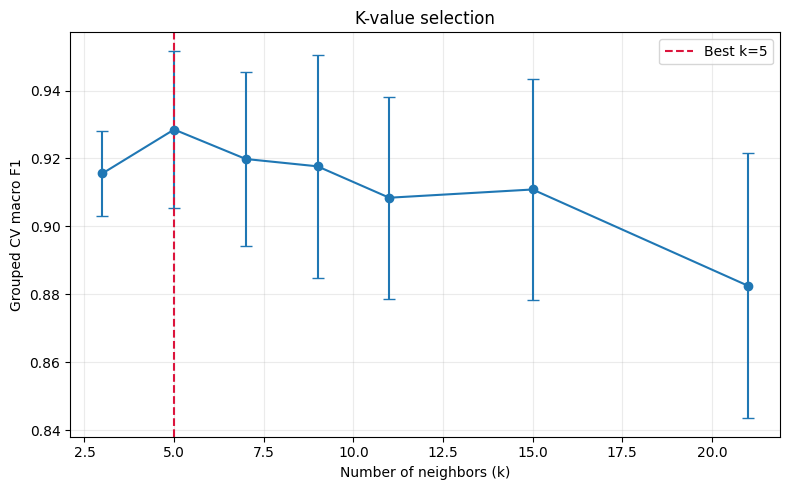

Distance comparison:
 distance  p  mean_cv_macro_f1  std_cv_macro_f1
euclidean  2          0.928532         0.023195
manhattan  1          0.933713         0.016782


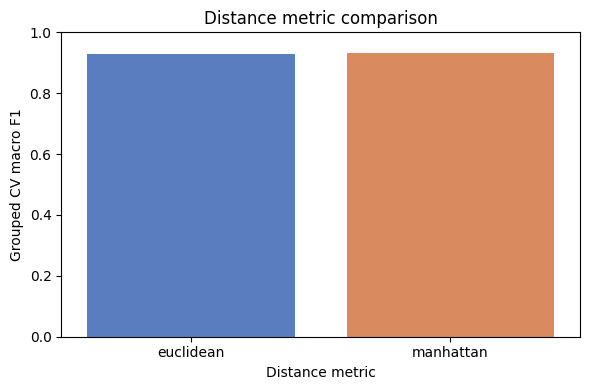

Weighting comparison:
 weights  mean_cv_macro_f1  std_cv_macro_f1
 uniform          0.933713         0.016782
distance          0.933713         0.016782


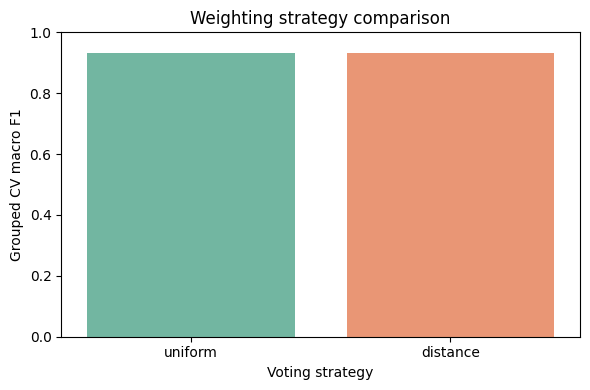

Final selected parameters: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
Final grouped CV macro F1: 0.9368
Learning curve:
 train_segments  train_macro_f1  cv_macro_f1   cv_std
            441             1.0     0.381567 0.023490
            882             1.0     0.378840 0.037003
           1323             1.0     0.374244 0.032164
           1764             1.0     0.522393 0.142479
           2205             1.0     0.936842 0.013237


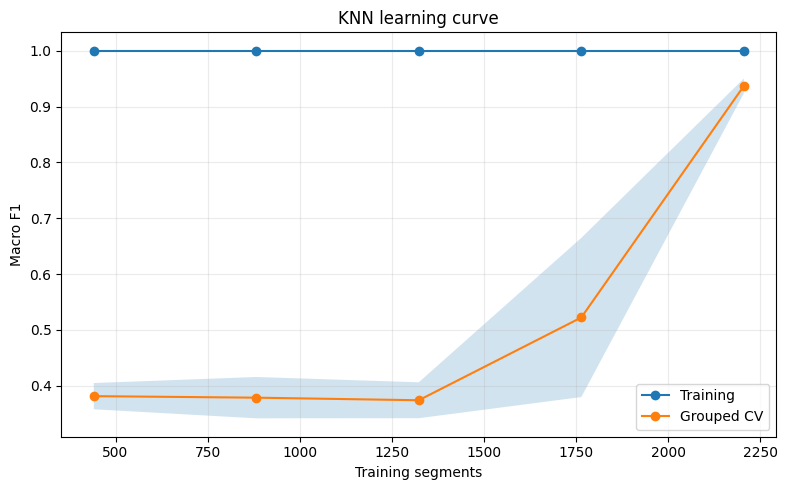

In [6]:
def grouped_cv_scores(estimator, X, y, groups, scoring="f1_macro"):
    scores = []
    train_scores = []
    for tr, va in cv.split(X, y, groups):
        fitted = clone(estimator)
        fitted.fit(X.iloc[tr], y[tr])
        pred = fitted.predict(X.iloc[va])
        train_pred = fitted.predict(X.iloc[tr])
        if scoring == "f1_macro":
            scores.append(f1_score(y[va], pred, average="macro", zero_division=0))
            train_scores.append(f1_score(y[tr], train_pred, average="macro", zero_division=0))
        else:
            raise ValueError(f"Unsupported scoring: {scoring}")
    return np.asarray(scores), np.asarray(train_scores)

# 5.1 Dummy baseline
dummy_scores, _ = grouped_cv_scores(DummyClassifier(strategy="most_frequent", random_state=RANDOM_SEED), X_train_raw, y_train, groups_train)
print(f"Dummy grouped CV macro F1: {dummy_scores.mean():.3f} +/- {dummy_scores.std():.3f}")

# 5.2 K-value experiment 
k_values = [3, 5, 7, 9, 11, 15, 21]
k_rows = []
for k in k_values:
    estimator = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, weights="distance", p=2, n_jobs=-1)),
    ])
    scores, train_scores = grouped_cv_scores(estimator, X_train_raw, y_train, groups_train)
    k_rows.append({"k": k, "mean_cv_macro_f1": scores.mean(), "std_cv_macro_f1": scores.std(), "mean_train_macro_f1": train_scores.mean()})
k_results = pd.DataFrame(k_rows)
best_k = int(k_results.loc[k_results["mean_cv_macro_f1"].idxmax(), "k"])
print("K experiment:")
print(k_results.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.errorbar(k_results["k"], k_results["mean_cv_macro_f1"], yerr=k_results["std_cv_macro_f1"], marker="o", capsize=4)
plt.axvline(best_k, linestyle="--", color="crimson", label=f"Best k={best_k}")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Grouped CV macro F1")
plt.title("K-value selection")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("plots/knn_k_selection_curve.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# 5.3 Distance comparison at the selected k
distance_rows = []
for name, p in [("euclidean", 2), ("manhattan", 1)]:
    estimator = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k, weights="distance", p=p, n_jobs=-1)),
    ])
    scores, _ = grouped_cv_scores(estimator, X_train_raw, y_train, groups_train)
    distance_rows.append({"distance": name, "p": p, "mean_cv_macro_f1": scores.mean(), "std_cv_macro_f1": scores.std()})
distance_results = pd.DataFrame(distance_rows)
print("Distance comparison:")
print(distance_results.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(data=distance_results, x="distance", y="mean_cv_macro_f1", hue="distance", legend=False, palette="muted")
plt.ylabel("Grouped CV macro F1")
plt.xlabel("Distance metric")
plt.title("Distance metric comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("plots/knn_distance_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()
selected_p = int(distance_results.loc[distance_results["mean_cv_macro_f1"].idxmax(), "p"])
selected_distance = str(distance_results.loc[distance_results["mean_cv_macro_f1"].idxmax(), "distance"])

# 5.4 Weighting comparison at selected k and distance
weight_rows = []
for weights in ["uniform", "distance"]:
    estimator = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k, weights=weights, p=selected_p, n_jobs=-1)),
    ])
    scores, _ = grouped_cv_scores(estimator, X_train_raw, y_train, groups_train)
    weight_rows.append({"weights": weights, "mean_cv_macro_f1": scores.mean(), "std_cv_macro_f1": scores.std()})
weight_results = pd.DataFrame(weight_rows)
print("Weighting comparison:")
print(weight_results.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(data=weight_results, x="weights", y="mean_cv_macro_f1", hue="weights", legend=False, palette="Set2")
plt.ylabel("Grouped CV macro F1")
plt.xlabel("Voting strategy")
plt.title("Weighting strategy comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("plots/knn_weighting_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()
selected_weights = str(weight_results.loc[weight_results["mean_cv_macro_f1"].idxmax(), "weights"])

# 5.5 Final compact grid search confirms the complete combination
param_grid = {
    "model__n_neighbors": k_values,
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_search = GridSearchCV(knn_pipeline, param_grid=param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True, return_train_score=True)
knn_search.fit(X_train_raw, y_train, groups=groups_train)
best_knn = knn_search.best_estimator_
best_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in knn_search.best_params_.items()}
knn_results = pd.DataFrame(knn_search.cv_results_).sort_values("rank_test_score")
knn_results.to_csv("models/knn_tuning_results.csv", index=False)

# 5.6 Select final configuration from the actual search result
print("Final selected parameters:", best_params)
print(f"Final grouped CV macro F1: {knn_search.best_score_:.4f}")

# 5.7 Learning curve on the grouped CV splitter
sizes, train_curve, validation_curve = learning_curve(
    knn_search.best_estimator_, X_train_raw, y_train, groups=groups_train, cv=cv,
    scoring="f1_macro", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
)
learning_results = pd.DataFrame({
    "train_segments": sizes,
    "train_macro_f1": train_curve.mean(axis=1),
    "cv_macro_f1": validation_curve.mean(axis=1),
    "cv_std": validation_curve.std(axis=1),
})
print("Learning curve:")
print(learning_results.to_string(index=False))
plt.figure(figsize=(8, 5))
plt.plot(sizes, learning_results["train_macro_f1"], marker="o", label="Training")
plt.plot(sizes, learning_results["cv_macro_f1"], marker="o", label="Grouped CV")
plt.fill_between(sizes, learning_results["cv_macro_f1"]-learning_results["cv_std"], learning_results["cv_macro_f1"]+learning_results["cv_std"], alpha=0.2)
plt.xlabel("Training segments")
plt.ylabel("Macro F1")
plt.title("KNN learning curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("plots/knn_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## 6. Evaluate Optimal K-Nearest Neighbors on Held-Out Test Set
6.1 Validation metrics
 6.2 Probability reliability
 6.3 Locked test metrics
 6.4 Classification report
 6.5 Latency

Validation metrics:
{
  "accuracy": 0.9853372434017595,
  "balanced_accuracy": 0.9046401832606995,
  "macro_precision": 0.9541272344900106,
  "macro_recall": 0.9046401832606995,
  "macro_f1": 0.9271205946721001,
  "roc_auc_macro": 0.9564232286995212,
  "log_loss": 0.23030305369869994
}
              precision    recall  f1-score   support

     ambient      1.000     0.842     0.914        19
     unknown      0.875     0.875     0.875         8
 vessel_like      0.987     0.997     0.992       314

    accuracy                          0.985       341
   macro avg      0.954     0.905     0.927       341
weighted avg      0.985     0.985     0.985       341

Validation confidence reliability:
               segments  mean_confidence  accuracy       gap
(-0.001, 0.6]         3         0.556894   0.00000  0.556894
(0.6, 0.8]            6         0.714254   1.00000 -0.285746
(0.8, 0.9]           13         0.858460   1.00000 -0.141540
(0.95, 1.0]         319         1.000000   0.99373  0

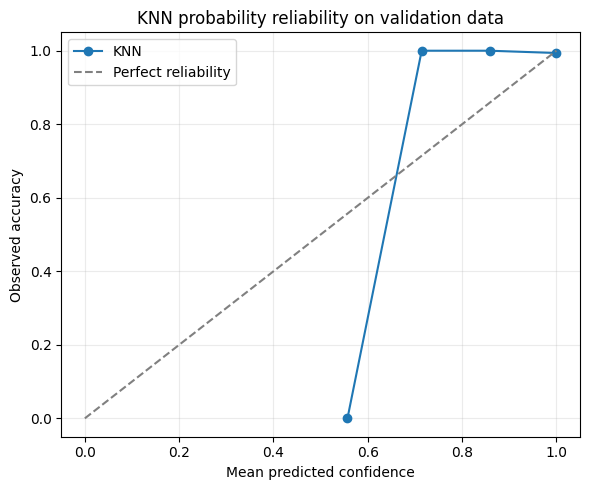

Final held-out test metrics:
{
  "algorithm": "K-Nearest Neighbors",
  "slug": "knn",
  "best_hyperparameters": {
    "model__n_neighbors": 7,
    "model__p": 1,
    "model__weights": "distance"
  },
  "grouped_cv_macro_f1": 0.9368423038298305,
  "accuracy": 0.991701244813278,
  "balanced_accuracy": 0.8925925925925927,
  "macro_precision": 0.9970824215900803,
  "macro_recall": 0.8925925925925927,
  "macro_f1": 0.939324272219009,
  "roc_auc_macro": 0.9852207949870153,
  "log_loss": 0.09254552537561235,
  "latency_ms": 2.3701969999819994,
  "classes": [
    "ambient",
    "unknown",
    "vessel_like"
  ],
  "feature_count": 66,
  "test_segments": 482
}
              precision    recall  f1-score   support

     ambient      1.000     0.900     0.947        20
     unknown      1.000     0.778     0.875         9
 vessel_like      0.991     1.000     0.996       453

    accuracy                          0.992       482
   macro avg      0.997     0.893     0.939       482
weighted avg   

In [7]:
def evaluate_classifier(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)
    result = {
        "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "macro_precision": float(precision_score(y, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
        "roc_auc_macro": float(roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(len(classes))))),
        "log_loss": float(log_loss(y, prob, labels=list(range(len(classes))))),
    }
    return result, pred, prob

val_metrics, val_pred, val_prob = evaluate_classifier(best_knn, X_val_raw, y_val)
print("Validation metrics:")
print(json.dumps(val_metrics, indent=2))
print(classification_report(y_val, val_pred, target_names=classes, digits=3, zero_division=0))

# Probability reliability on validation data. 
val_confidence = val_prob.max(axis=1)
val_correct = val_pred == y_val
confidence_bins = pd.cut(val_confidence, [0, 0.6, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
reliability = pd.DataFrame({"confidence": val_confidence, "correct": val_correct}).groupby(confidence_bins, observed=True).agg(segments=("confidence", "size"), mean_confidence=("confidence", "mean"), accuracy=("correct", "mean"))
reliability["gap"] = reliability["mean_confidence"] - reliability["accuracy"]
print("Validation confidence reliability:")
print(reliability)

plt.figure(figsize=(6, 5))
if len(reliability):
    plt.plot(reliability["mean_confidence"], reliability["accuracy"], marker="o", label="KNN")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect reliability")
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("KNN probability reliability on validation data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("plots/knn_probability_reliability.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

latency_start = time.perf_counter()
for _ in range(100):
    best_knn.predict(X_test_raw.iloc[:1])
latency_ms = (time.perf_counter() - latency_start) / 100 * 1000

test_metrics_base, test_pred, test_prob = evaluate_classifier(best_knn, X_test_raw, y_test)
test_metrics = {
    "algorithm": ALGO_NAME, "slug": FILE_SLUG,
    "best_hyperparameters": best_params,
    "grouped_cv_macro_f1": float(knn_search.best_score_),
    **test_metrics_base,
    "latency_ms": float(latency_ms),
    "classes": classes, "feature_count": len(feature_cols),
    "test_segments": int(len(y_test)),
}
print("Final held-out test metrics:")
print(json.dumps(test_metrics, indent=2))
print(classification_report(y_test, test_pred, target_names=classes, digits=3, zero_division=0))

## 7.Confusion Matrix & Multi-Class ROC Curves

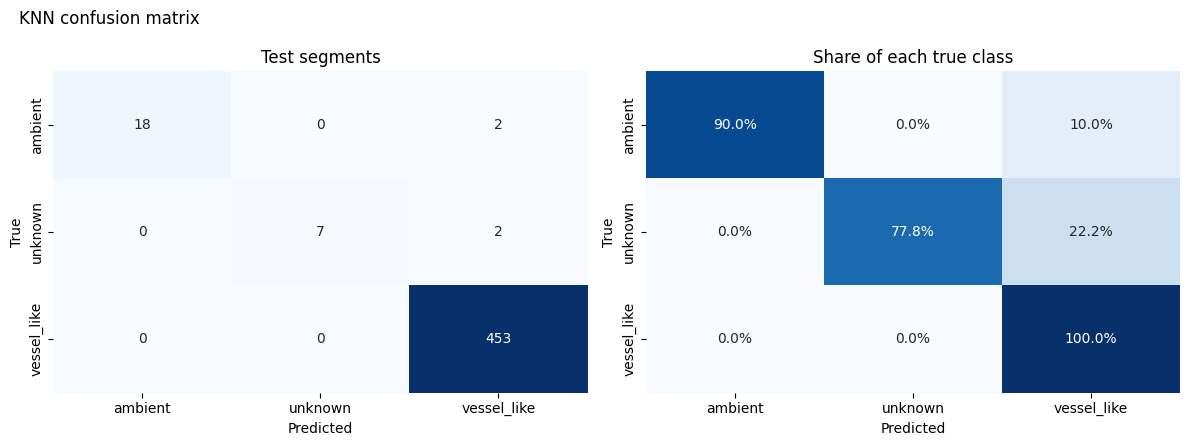

In [8]:
# Confusion matrix
cm = confusion_matrix(y_test, test_pred, labels=list(range(len(classes))))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Test segments")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Share of each true class")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
fig.suptitle("KNN confusion matrix", x=0.02, ha="left")
fig.tight_layout()
fig.savefig("plots/confusion_matrix_knn.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

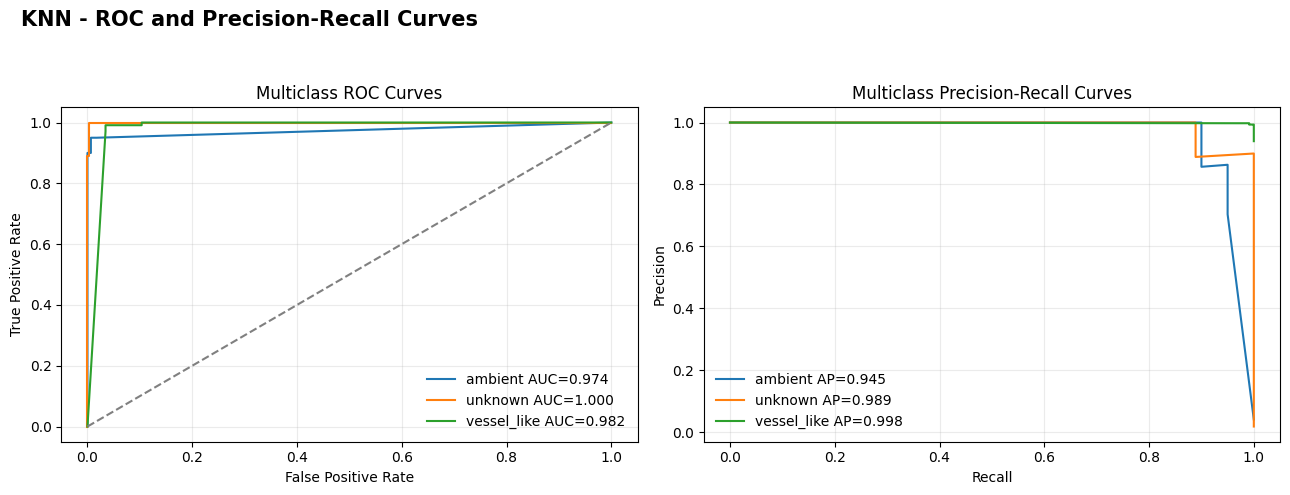

In [9]:
#ROC and Precision-Recall Curves

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, class_name in enumerate(classes):
    binary = (y_test == i).astype(int)

    fpr, tpr, _ = roc_curve(binary, test_prob[:, i])
    axes[0].plot(
        fpr, tpr,
        label=f"{class_name} AUC={auc(fpr, tpr):.3f}"
    )

    precision, recall, _ = precision_recall_curve(
        binary, test_prob[:, i]
    )

    axes[1].plot(
        recall, precision,
        label=f"{class_name} AP={average_precision_score(binary, test_prob[:, i]):.3f}"
    )

# ROC Curve
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Multiclass ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

# Precision-Recall Curve
axes[1].set_title("Multiclass Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

# Main heading
fig.suptitle("KNN - ROC and Precision-Recall Curves", x=0.02, ha="left",
             fontsize=15, fontweight="bold")

fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    "plots/roc_pr_curves_knn.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [10]:
#  Error analysis by class and source
meta_path = Path("../data/metadata/master_metadata.csv")
if meta_path.exists():
    metadata = pd.read_csv(meta_path)
    source_map = dict(zip(metadata["clip_id"], metadata["source_dataset"]))
    error_df = pd.DataFrame({
        "source_clip_id": df.loc[test_mask, "source_clip_id"].to_numpy(),
        "true": [classes[i] for i in y_test],
        "predicted": [classes[i] for i in test_pred],
        "confidence": test_prob.max(axis=1),
    })
    error_df["source_dataset"] = error_df["source_clip_id"].map(source_map).fillna("Unknown source")
    error_df["correct"] = error_df["true"] == error_df["predicted"]
    print("Recall by true class:")
    print(error_df.groupby("true")["correct"].mean())
    print("Accuracy by source:")
    print(error_df.groupby("source_dataset")["correct"].agg(["size", "mean"]))
    print("Most confident errors:")
    print(error_df.loc[~error_df["correct"]].sort_values("confidence", ascending=False).head(10))
else:
    print(f"Metadata not found; source-wise error analysis skipped: {meta_path}")

Recall by true class:
true
ambient        0.900000
unknown        0.777778
vessel_like    1.000000
Name: correct, dtype: float64
Accuracy by source:
                size      mean
source_dataset                
DeepShip         398  1.000000
ShipsEar          42  0.952381
Synthetic         42  0.952381
Most confident errors:
    source_clip_id     true    predicted  confidence source_dataset  correct
24    94f1fb34-d9f  ambient  vessel_like    1.000000       ShipsEar    False
360   640cb7f1-6a1  unknown  vessel_like    0.856703      Synthetic    False
4     4165cba0-672  ambient  vessel_like    0.854362       ShipsEar    False
357   9acd7831-65c  unknown  vessel_like    0.559798      Synthetic    False


## 8. Model Interpretability & Feature Importance

Top permutation-importance features:
                    feature  mean_f1_drop  std_f1_drop
spectral_contrast_band4_min      0.020419     0.010209
                 mfcc_2_max      0.020419     0.010209
spectral_contrast_band6_max      0.018421     0.014890
spectral_contrast_band3_min      0.009401     0.014805
                freq_spread      0.006673     0.012118
               snr_estimate      0.006622     0.012606
           delta_mfcc_1_max      0.003204     0.009919
                    rms_std      0.002718     0.012740
          delta_mfcc_2_mean      0.002374     0.016110
                 mfcc_1_std      0.000000     0.000000
                 mfcc_1_max      0.000000     0.000000
      spectral_flatness_min      0.000000     0.000000
                mfcc_4_mean      0.000000     0.000000
   spectral_flatness_median      0.000000     0.000000
      spectral_flatness_max      0.000000     0.000000


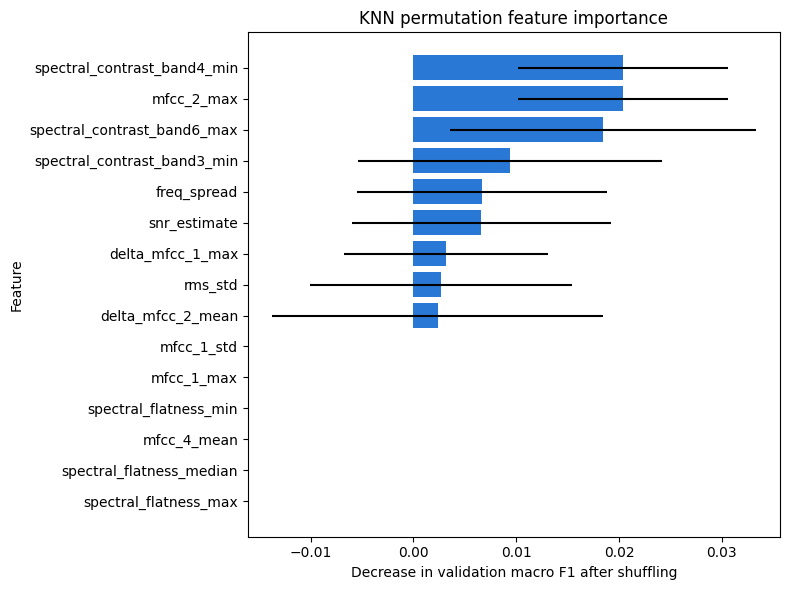

In [11]:
# 8.5 Permutation importance on validation data, not the locked test set
permutation = permutation_importance(best_knn, X_val_raw, y_val, scoring="f1_macro", n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1)
importance = pd.DataFrame({"feature": feature_cols, "mean_f1_drop": permutation.importances_mean, "std_f1_drop": permutation.importances_std}).sort_values("mean_f1_drop", ascending=False)
print("Top permutation-importance features:")
print(importance.head(15).to_string(index=False))
top = importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["mean_f1_drop"], xerr=top["std_f1_drop"], color="#2a78d6")
plt.xlabel("Decrease in validation macro F1 after shuffling")
plt.ylabel("Feature")
plt.title("KNN permutation feature importance")
plt.tight_layout()
plt.savefig("plots/permutation_importance_knn.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## 9. Export Model Artifacts for Final Showdown

In [12]:
# Save artifacts
joblib.dump(best_knn, "models/model_knn.joblib")
joblib.dump(best_knn.named_steps["scaler"], "models/scaler_knn.joblib")
joblib.dump(label_encoder, "models/label_encoder_knn.joblib")

metadata = {
    "algorithm": ALGO_NAME,
    "feature_names": feature_cols,
    "feature_count": len(feature_cols),
    "classes": classes,
    "best_parameters": best_params,
    "split_sizes": {"train": len(X_train_raw), "validation": len(X_val_raw), "test": len(X_test_raw)},
    "grouping_column": "source_clip_id",
    "cv": "5-fold StratifiedGroupKFold",
}
with open("models/knn_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
with open("models/metrics_knn.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

In [13]:
#Reload verification
saved_model = joblib.load("models/model_knn.joblib")
saved_scaler = joblib.load("models/scaler_knn.joblib")
saved_encoder = joblib.load("models/label_encoder_knn.joblib")
saved_pred = saved_model.predict(X_test_raw)
saved_prob = saved_model.predict_proba(X_test_raw)
assert list(saved_encoder.classes_) == classes
assert np.array_equal(saved_pred, test_pred)
assert np.allclose(saved_prob, test_prob)
assert saved_scaler is not None
print("Reloaded model reproduces test predictions and probabilities.")

Reloaded model reproduces test predictions and probabilities.


## Conclusion

In [14]:
print("\nConclusion:")
print(f"Selected KNN configuration: {best_params}")
print(f"Grouped CV macro F1: {knn_search.best_score_:.3f}")
print(f"Held-out test macro F1: {test_metrics['macro_f1']:.3f}")
print(f"Held-out test balanced accuracy: {test_metrics['balanced_accuracy']:.3f}")
print("The minority-class results should be interpreted with the small ambient and unknown test supports in mind.")


Conclusion:
Selected KNN configuration: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
Grouped CV macro F1: 0.937
Held-out test macro F1: 0.939
Held-out test balanced accuracy: 0.893
The minority-class results should be interpreted with the small ambient and unknown test supports in mind.
